# DDC Stage B - Single-image quickstart

This notebook shows the recommended first validation workflow: load a repository-style pre-v7.3 MAT input, inspect it, select one image, run a short smoke test, and interpret the result.

**Important:** `load_dataset()` is for raw pre-v7.3 inputs. Python-generated v7.3 checkpoints must be opened with `load_checkpoint()`.

In [1]:
from pathlib import Path
from time import perf_counter
import numpy as np
import matplotlib.pyplot as plt
import ddc
from ddc import DDCDataset, DDCConfig, CheckpointWriter, load_dataset, run_ddc

print("DDC version:", ddc.__version__)

DDC version: 0.1.0


## 1. Load and inspect the input

Replace the path below with a raw DDC MAT file in pre-v7.3 format.

In [3]:
INPUT_MAT = Path("C:\\Users\\maula\\Desktop\\PhD FIles\\ddc\\data\\Split_Example_3d_2darkstate_random_data.mat")
assert INPUT_MAT.exists(), INPUT_MAT
dataset = load_dataset(INPUT_MAT)
print("n_images:", dataset.n_images)
for i, (loc, fr) in enumerate(zip(dataset.localizations, dataset.frames)):
    print(i, "localizations", loc.shape, loc.dtype, "frames", fr.shape, fr.dtype)

n_images: 30
0 localizations (4438, 3) float64 frames (4438,) uint16
1 localizations (4990, 3) float64 frames (4990,) uint16
2 localizations (4465, 3) float64 frames (4465,) uint16
3 localizations (4302, 3) float64 frames (4302,) uint16
4 localizations (3976, 3) float64 frames (3976,) uint16
5 localizations (4000, 3) float64 frames (4000,) uint16
6 localizations (4276, 3) float64 frames (4276,) uint16
7 localizations (3982, 3) float64 frames (3982,) uint16
8 localizations (3958, 3) float64 frames (3958,) uint16
9 localizations (3988, 3) float64 frames (3988,) uint16
10 localizations (4857, 3) float64 frames (4857,) uint16
11 localizations (4714, 3) float64 frames (4714,) uint16
12 localizations (4744, 3) float64 frames (4744,) uint16
13 localizations (4853, 3) float64 frames (4853,) uint16
14 localizations (4000, 3) float64 frames (4000,) uint16
15 localizations (3996, 3) float64 frames (3996,) uint16
16 localizations (3972, 3) float64 frames (3972,) uint16
17 localizations (4285, 3) f

## 2. Select one image

The helper below subsets all aligned per-image fields together. Python indices start at zero.

In [4]:
def subset_dataset(dataset: DDCDataset, indices):
    indices = list(indices)

    def cells(values):
        return [np.asarray(values[i]).copy() for i in indices]

    def optional_cells(values):
        return None if values is None else cells(values)

    def optional_vector(values):
        if values is None:
            return None
        return np.asarray(values)[indices].copy()

    return DDCDataset(
        localizations=cells(dataset.localizations),
        frames=cells(dataset.frames),
        true_localizations=cells(dataset.true_localizations),
        photons=optional_cells(dataset.photons),
        came_from_image=optional_vector(dataset.came_from_image),
        addon=optional_vector(dataset.addon),
        cuts=tuple(optional_cells(x) for x in dataset.cuts),
        parameters_to_split=optional_cells(dataset.parameters_to_split),
        source=dataset.source,
        mat_passthrough=dict(dataset.mat_passthrough),
    )

IMAGE_INDEX = 0
test_dataset = subset_dataset(dataset, [IMAGE_INDEX])
print("selected images:", test_dataset.n_images)
print("localizations:", test_dataset.localizations[0].shape)
print("frames:", test_dataset.frames[0].shape, test_dataset.frames[0].dtype)

selected images: 1
localizations: (4438, 3)
frames: (4438,) uint16


## 3. Configure a smoke test

`stepper=12` is useful only to verify that the end-to-end path works. It is not intended as a converged scientific run. The source default is `stepper=100`.

In [5]:
config = DDCConfig(
    resolution=80.0,
    stepper=12,
    n_f=200,
    photon_weighted_correction=1,
    timer=30.0,
)

rngs = [np.random.default_rng(123)]
print(config)

DDCConfig(resolution=80.0, stepper=12, n_f=200, photon_weighted_correction=1, timer=30.0)


## 4. Run DDC

In [10]:
# Error fixing
test_dataset.frames = [
    np.asarray(frame, dtype=np.float64)
    for frame in test_dataset.frames
]
if test_dataset.photons is not None:
    test_dataset.photons = [
        np.asarray(values, dtype=np.float64)
        for values in test_dataset.photons
    ]

In [11]:
t0 = perf_counter()
result = run_ddc(test_dataset, config, rngs=rngs)
elapsed = perf_counter() - t0
print(f"elapsed: {elapsed:.3f} s")

elapsed: 638.833 s


## 5. Inspect the result

In [12]:
raw = test_dataset.localizations[0]
truth = test_dataset.true_localizations[0]
final = result.final_localizations[0]
state = result.states[0]

print("RAW:", raw.shape)
print("TRUTH:", truth.shape)
print("FINAL:", None if final is None else final.shape)
print("Step:", state.step)
print("Likelihood history:", state.likelihood)
print("Score history:", state.score)
print("Number history:", state.number_of_localizations)

if truth.size and final is not None:
    n_true = len(truth)
    print("Raw counting error:", len(raw) - n_true)
    print("DDC counting error:", len(final) - n_true)
    print("DDC absolute relative count error:", abs(len(final)-n_true)/n_true)

RAW: (4438, 3)
TRUTH: (1093, 3)
FINAL: (1087, 3)
Step: 12
Likelihood history: [-2127812.95833611 -2127813.16136474 -2127813.37816617]
Score history: [0.10024722 0.10027125 0.10189942]
Number history: [1087. 1087. 1088.]
Raw counting error: 3345
DDC counting error: -6
DDC absolute relative count error: 0.0054894784995425435


## 6. Plot likelihood, score and localization-count history

Likelihood is not expected to be monotonic: the Metropolis rule can accept lower-likelihood states. The final output stores the best-likelihood state separately.

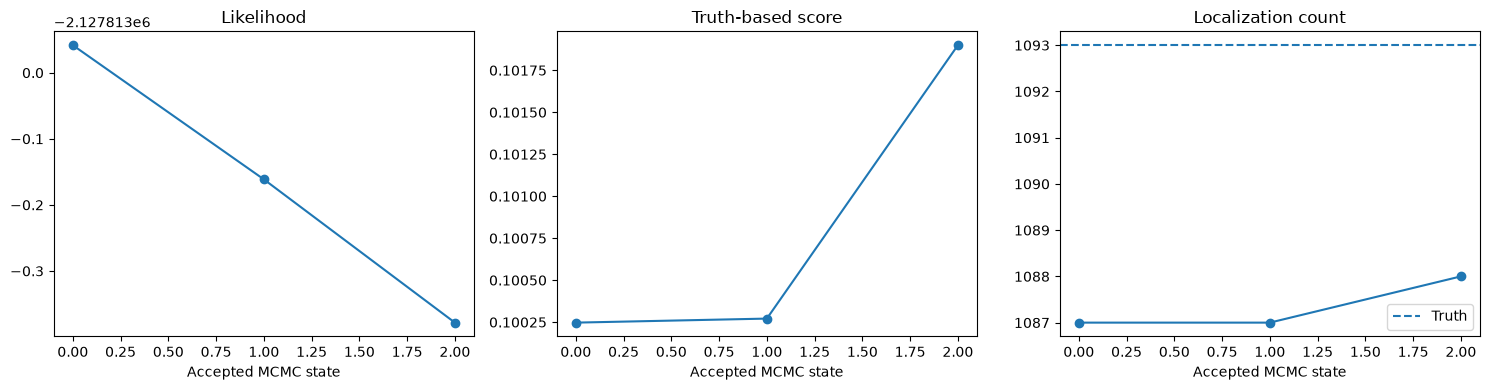

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(state.likelihood, marker="o")
axes[0].set_title("Likelihood")
axes[0].set_xlabel("Accepted MCMC state")
if state.score.size:
    axes[1].plot(state.score, marker="o")
axes[1].set_title("Truth-based score")
axes[1].set_xlabel("Accepted MCMC state")
axes[2].plot(state.number_of_localizations, marker="o")
if truth.size:
    axes[2].axhline(len(truth), linestyle="--", label="Truth")
    axes[2].legend()
axes[2].set_title("Localization count")
axes[2].set_xlabel("Accepted MCMC state")
plt.tight_layout()

## 7. Compare Raw, Truth and DDC projections

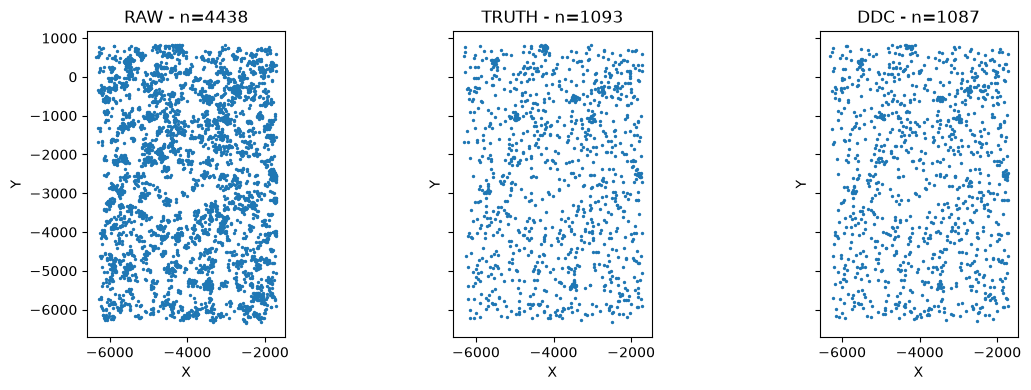

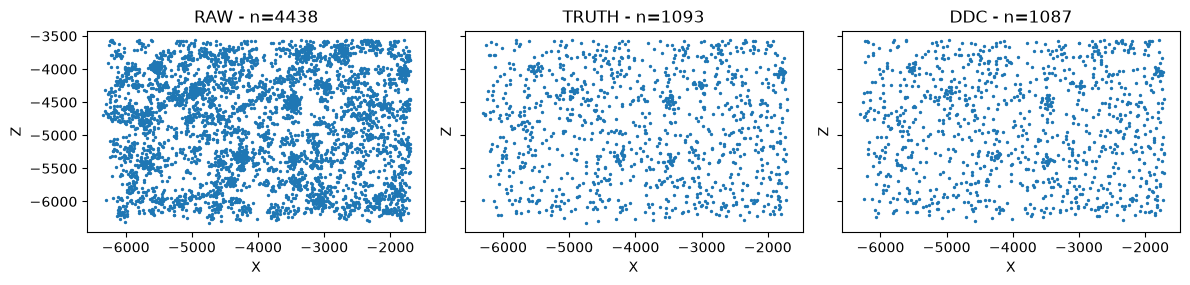

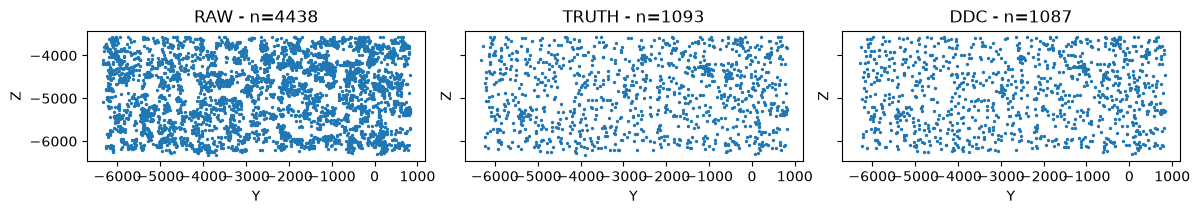

In [14]:
def plot_projection(raw, truth, final, a, b, labels):
    datasets = [(raw, f"RAW - n={len(raw)}"), (truth, f"TRUTH - n={len(truth)}"), (final, f"DDC - n={len(final)}")]
    fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
    for ax, (data, title) in zip(axes, datasets):
        ax.scatter(data[:, a], data[:, b], s=2)
        ax.set_title(title)
        ax.set_xlabel(labels[0])
        ax.set_ylabel(labels[1])
        ax.set_aspect("equal", adjustable="box")
    plt.tight_layout()

if truth.size and final is not None:
    plot_projection(raw, truth, final, 0, 1, ("X", "Y"))
    if raw.shape[1] >= 3:
        plot_projection(raw, truth, final, 0, 2, ("X", "Z"))
        plot_projection(raw, truth, final, 1, 2, ("Y", "Z"))

## 8. Inspect trajectory sizes

Number of trajectory labels: 1087
Mean trajectory size: 4.082796688132475
Maximum trajectory size: 28


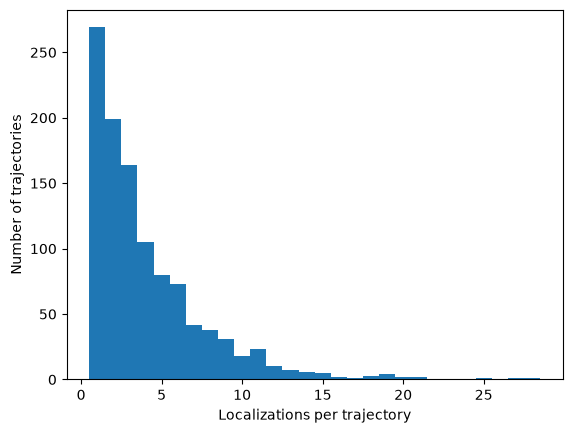

In [15]:
traj = result.trajectories[0]
labels, counts = np.unique(traj, return_counts=True)
print("Number of trajectory labels:", len(labels))
print("Mean trajectory size:", counts.mean())
print("Maximum trajectory size:", counts.max())
plt.hist(counts, bins=np.arange(1, counts.max()+2)-0.5)
plt.xlabel("Localizations per trajectory")
plt.ylabel("Number of trajectories")
plt.show()

## 9. Optional checkpoint output

In [ ]:
# To save a real run, construct the writer BEFORE calling run_ddc:
# writer = CheckpointWriter("Analyzed_python_output.mat", test_dataset, config)
# result = run_ddc(test_dataset, config, rngs=[np.random.default_rng(123)], checkpoint_callback=writer)